# Valenbisi: final analysis

Same question as `01_analysis.ipynb`: **on a given type of day and hour, how often is there a bike at the departure station and a free dock at the destination?**

What changed:
- **More data.** About three times the working days of the first analysis (18 with complete collection, against 6).
- **The cleaning now lives in dbt** (`dbt/`), not in this notebook. The five rules found in `01_analysis.ipynb` are dbt models, checked by automated tests every day in GitHub Actions. This notebook only reads the final tables (marts) from the `analytics` schema.
- **Uncertainty is shown, not only described:** the trip chart carries a 95% confidence band.

Sections:
1. Extraction
2. Data quality
3. A real trip: 74 to 105
4. The whole city at 8:00
5. Conclusions and limitations

Not split by weekday on purpose: with 3-4 working days of each weekday, every weekday/hour cell rests on 6-8 readings, so differences between weekdays would be noise.

Charts are saved to `docs/img/` for the README.

## 1. Extraction

The tables come from the dbt marts. Before running this notebook, `dbt build` must have run (GitHub Actions does it every day at 05:23 UTC).

In [43]:
import os
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from dotenv import load_dotenv
from sqlalchemy import create_engine

load_dotenv()
url = os.environ["DATABASE_URL"].replace("postgresql://", "postgresql+psycopg://", 1)
engine = create_engine(url)

FIG_DIR = Path("../docs/img")
FIG_DIR.mkdir(parents=True, exist_ok=True)


def read(table):
    """Read a whole dbt mart from the analytics schema."""
    return pd.read_sql(f"SELECT * FROM analytics.{table}", engine)


readings = read("fct_readings")          # one clean reading per station and 30-min slot
stations = read("dim_stations")
profile = read("mart_station_profile")   # % bike / dock by station, type of day and hour
trips = read("mart_trip_success")        # paired readings, origin and destination
cleaning_log = read("rpt_cleaning_log")

for name, df in [("readings", readings), ("stations", stations), ("profile", profile),
                 ("trips", trips), ("cleaning_log", cleaning_log)]:
    print(f"{name:13} {df.shape}")

readings      (380875, 14)
stations      (273, 8)
profile       (13056, 8)
trips         (48, 11)
cleaning_log  (5, 4)


In [44]:
# Which period does this analysis cover?
days = readings.groupby("local_date")["day_type"].first()

# A day counts as collected if it has at least half of its 48 runs per station.
# Without this, days with only a handful of readings (the 2-5 November outage)
# would be counted as full working days.
per_station = (readings.groupby("local_date").size()
               / readings.groupby("local_date")["station_id"].nunique())
collected = per_station >= 24

print(f"From {days.index.min()} to {days.index.max()}")
print(f"Working days with complete collection: {((days == 'workday') & collected).sum()} "
      f"(of {(days == 'workday').sum()} in the period)")
print(f"Weekend or holiday days with complete collection: {((days != 'workday') & collected).sum()}")
print("Days left out of the count:", list(per_station[~collected].index))

From 2026-10-03 to 2026-11-05
Working days with complete collection: 18 (of 22 in the period)
Weekend or holiday days with complete collection: 12
Days left out of the count: [datetime.date(2026, 11, 2), datetime.date(2026, 11, 3), datetime.date(2026, 11, 4), datetime.date(2026, 11, 5)]


## 2. Data quality

The cleaning rules run in dbt; `rpt_cleaning_log` records how many readings each one removes. If a rule suddenly removed most of the data, the dbt test `assert_cleaning_keeps_most_readings` would fail.

In [45]:
log = cleaning_log.copy()
log["pct_of_period"] = (100 * log["rows_left"] / log.loc[log["step"] == 1, "rows_left"].iloc[0]).round(1)
log

,step,rule,rows_left,rows_removed,pct_of_period
0,0,raw readings,421023,0,102.0
1,1,from collection start,412828,8195,100.0
2,2,delay <= 60 min,412218,610,99.9
3,3,in service,410728,1490,99.5
4,4,one reading per slot,380875,29853,92.3


In [46]:
# Chart style, shared by every chart below (same as 01_analysis.ipynb)
plt.rcParams.update({
    "figure.figsize": (9, 4.5),
    "figure.facecolor": "#fcfcfb",
    "axes.facecolor": "#fcfcfb",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "axes.grid.axis": "y",
    "grid.color": "#e4e3df",
    "axes.edgecolor": "#a3a29c",
    "axes.labelcolor": "#52514e",
    "axes.titlecolor": "#0b0b0b",
    "xtick.color": "#52514e",
    "ytick.color": "#52514e",
    "text.color": "#52514e",
    "font.size": 11,
})
BLUE, ORANGE = "#2a78d6", "#eb6834"
SURFACE, INK, INK_2 = "#fcfcfb", "#0b0b0b", "#52514e"
# One-hue sequential ramp (light = low, dark = high)
BLUES = LinearSegmentedColormap.from_list(
    "blues", ["#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5", "#256abf", "#184f95", "#0d366b"])


def save(fig, name):
    fig.savefig(FIG_DIR / f"{name}.png", dpi=200, bbox_inches="tight", facecolor=SURFACE)

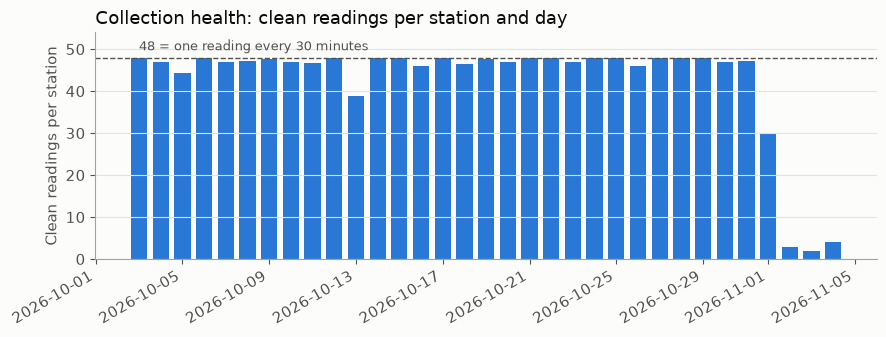

,readings,stations,per_station
local_date,,,
2026-10-13,10575,272,38.878676
2026-11-01,7980,266,30.000000
2026-11-02,810,272,2.977941
2026-11-03,543,272,1.996324
2026-11-04,1088,272,4.000000


In [47]:
# Is the collection complete? A run every 30 minutes gives 48 readings per station and day.
# The last day is left out: it is still being collected, so it always looks incomplete
complete = readings[readings["local_date"] < readings["local_date"].max()]
per_day = complete.groupby("local_date").agg(readings=("station_id", "size"),
                                            stations=("station_id", "nunique"))
per_day["per_station"] = per_day["readings"] / per_day["stations"]

fig, ax = plt.subplots(figsize=(9, 3.5))
ax.bar(pd.to_datetime(per_day.index), per_day["per_station"], color=BLUE, width=0.75)
ax.axhline(48, color=INK_2, linewidth=1, linestyle="--")
ax.text(pd.to_datetime(per_day.index.min()), 49, "48 = one reading every 30 minutes",
        va="bottom", color=INK_2, fontsize=9)
ax.set_ylim(0, 54)
ax.set_ylabel("Clean readings per station")
ax.set_title("Collection health: clean readings per station and day", loc="left")
fig.autofmt_xdate()
fig.tight_layout()
save(fig, "collection_health")
plt.show()

per_day[per_day["per_station"] < 40]   # days with clear gaps

**Reading it:** days well below 48 are API outages or pipeline failures; the table above lists them. They reduce the sample but do not bias it, unless an outage always hits the same hours.

## 3. A real trip: station 74 (Mercado Algirós) to station 105 (UPV)

`mart_trip_success` pairs the readings of both stations taken in the same 30-minute slot and counts how often there was a bike at the origin **and** a free dock at the destination. `pct_naive` is the shortcut of multiplying the two separate probabilities, kept to show why pairing matters.

**How sure can we be?** Each percentage rests on a few dozen paired readings. The band is a 95% Wilson confidence interval: with that many readings, the true value is plausibly anywhere inside it. Wilson is used instead of the textbook `p ± 1.96·√(p(1-p)/n)` because that formula breaks near 0% and 100%, exactly where most of these values are.

One caveat makes the band **too narrow, not too wide**: the interval assumes independent readings, but the two readings of the same day and hour are correlated (a full station at 8:00 is usually still full at 8:30). The real uncertainty is somewhat larger.

In [48]:
def wilson(p, n, z=1.96):
    """95% Wilson score interval for a proportion p observed over n trials."""
    denom = 1 + z**2 / n
    center = (p + z**2 / (2 * n)) / denom
    half = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / denom
    return center - half, center + half


ORIGIN, DESTINATION = 74, 105
t = trips[(trips["origin_id"] == ORIGIN) & (trips["destination_id"] == DESTINATION)
          & (trips["day_type"] == "workday")].sort_values("local_hour").set_index("local_hour")
low, high = wilson(t["pct_trip"] / 100, t["paired_readings"])
t["ci_low"], t["ci_high"] = (100 * low).round(1), (100 * high).round(1)

t.loc[6:11, ["paired_readings", "pct_bike_at_origin", "pct_dock_at_destination",
             "pct_naive", "pct_trip", "ci_low", "ci_high"]]

,paired_readings,pct_bike_at_origin,pct_dock_at_destination,pct_naive,pct_trip,ci_low,ci_high
local_hour,,,,,,,
6,35,100.0,100.0,100.0,100.0,90.1,100.0
7,36,100.0,100.0,100.0,100.0,90.4,100.0
8,36,88.9,52.8,46.9,50.0,34.5,65.5
9,35,77.1,45.7,35.3,37.1,23.1,53.6
10,37,64.9,51.4,33.3,35.1,21.8,51.2
11,36,72.2,88.9,64.2,66.7,50.4,79.8


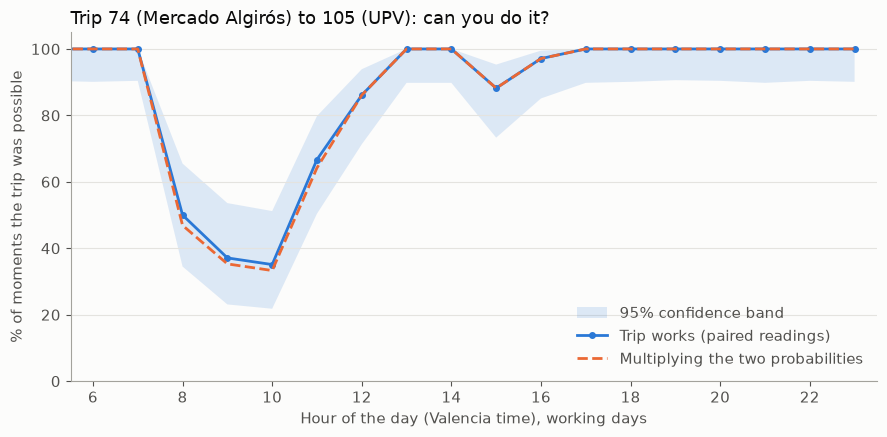

In [49]:
fig, ax = plt.subplots()
ax.fill_between(t.index, t["ci_low"], t["ci_high"], color=BLUE, alpha=0.15, linewidth=0,
                label="95% confidence band")
ax.plot(t.index, t["pct_trip"], color=BLUE, linewidth=2, marker="o", markersize=4,
        label="Trip works (paired readings)")
ax.plot(t.index, t["pct_naive"], color=ORANGE, linewidth=2, linestyle="--",
        label="Multiplying the two probabilities")

ax.set_ylim(0, 105)
ax.set_xlim(5.5, 23.5)
ax.set_xticks(range(6, 24, 2))
ax.set_xlabel("Hour of the day (Valencia time), working days")
ax.set_ylabel("% of moments the trip was possible")
ax.set_title("Trip 74 (Mercado Algirós) to 105 (UPV): can you do it?", loc="left")
ax.legend(loc="lower right", frameon=False)
fig.tight_layout()
save(fig, "trip_74_105")
plt.show()

**Findings:** Before 8:00 the trip from 74 to 105 worked in every paired reading: 100% at 6:00 and 7:00 (95% band 90-100%). Between 8:00 and 10:00 it worked only between one time in three and one time in two: 50% at 8:00 (band 35-66%), 37% at 9:00 and 35% at 10:00, recovering to 67% at 11:00. At 8:00 and 9:00 the bottleneck is the destination (a free dock at 105 only 53% and 46% of the time), but by 10:00 the origin fails too: there is a bike at 74 only 65% of the time.

Multiplying the two separate probabilities gives almost the same values as pairing the readings (at most 3 points apart, well inside the band). The first analysis, with 6 working days, suggested the pairing mattered; with 18 days there is no evidence that it does. What the band does not allow is ranking 8:00, 9:00 and 10:00 against each other: their intervals overlap almost completely.

## 4. The whole city at 8:00 on a working day

Every station, coloured by how often it was full at 8:00. Stations with fewer than `MIN_READINGS` readings in that hour are left out.

The street map behind the points is downloaded from OpenStreetMap by `contextily`. Without internet the chart is drawn without it.

272 stations with at least 20 readings at 8:00


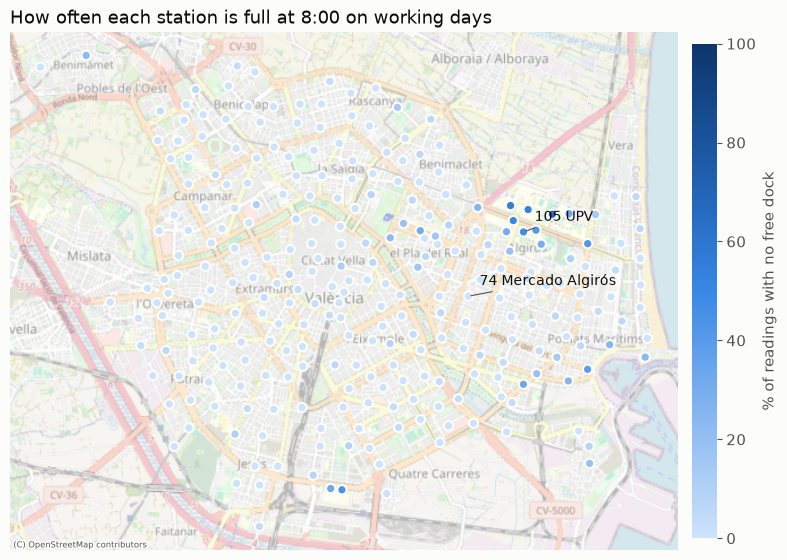

In [50]:
HOUR = 8
MIN_READINGS = 20

at_hour = (profile[(profile["day_type"] == "workday") & (profile["local_hour"] == HOUR)
                   & (profile["readings"] >= MIN_READINGS)]
           .merge(stations[["station_id", "latitude", "longitude"]], on="station_id"))
at_hour["pct_full"] = 100 - at_hour["pct_dock"]
print(f"{len(at_hour)} stations with at least {MIN_READINGS} readings at {HOUR}:00")

fig, ax = plt.subplots(figsize=(8, 8))
# Draw the worst stations last, so they sit on top where points overlap
at_hour = at_hour.sort_values("pct_full")
points = ax.scatter(at_hour["longitude"], at_hour["latitude"], c=at_hour["pct_full"],
                    cmap=BLUES, vmin=0, vmax=100, s=45, edgecolors=SURFACE, linewidths=1.5, zorder=3)

for sid, name in [(105, "105 UPV"), (ORIGIN, "74 Mercado Algirós")]:
    row = at_hour[at_hour["station_id"] == sid]
    if not row.empty:
        ax.annotate(name, (row["longitude"].iloc[0], row["latitude"].iloc[0]), xytext=(8, 8),
                    textcoords="offset points", fontsize=10, color=INK, zorder=4,
                    arrowprops={"arrowstyle": "-", "color": INK_2, "linewidth": 0.8})

# A degree of longitude is shorter than a degree of latitude at Valencia's latitude
ax.set_aspect(1 / np.cos(np.radians(at_hour["latitude"].mean())))
ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
for side in ["left", "bottom"]:
    ax.spines[side].set_visible(False)

try:
    import contextily as ctx
    # OpenStreetMap needs no API key (CARTO's tiles now do). Faded so the points stand out.
    # OpenStreetMap's tile policy requires a User-Agent that identifies the app;
    # without it the server returns "Access blocked" images instead of the map.
    ctx.add_basemap(ax, crs="EPSG:4326", source=ctx.providers.OpenStreetMap.Mapnik,
                    headers={"User-Agent": "valenbisi-pipeline/1.0 (https://github.com/daniv14-hub/valenbisi-pipeline)"},
                    alpha=0.5, attribution_size=6, zorder=1)
except Exception as error:  # no internet or contextily not installed
    print(f"Street map not added ({type(error).__name__}); drawing points only.")

ax.set_title(f"How often each station is full at {HOUR}:00 on working days", loc="left")
cbar = fig.colorbar(points, ax=ax, fraction=0.035, pad=0.02, shrink=0.7)
cbar.set_label("% of readings with no free dock")
cbar.outline.set_visible(False)
fig.tight_layout()
save(fig, "map_full_at_8")
plt.show()

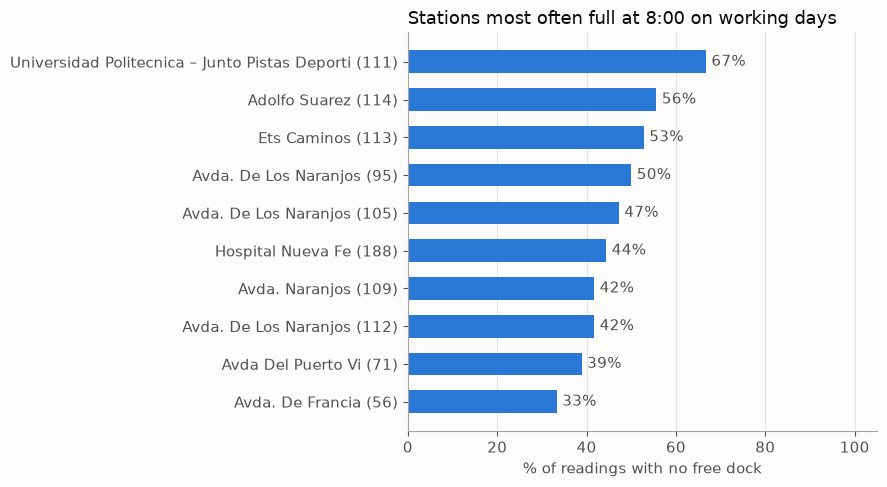

,station_label,readings,pct_full
270,Universidad Politecnica – Junto Pistas Deporti...,36.0,66.7
39,Adolfo Suarez (114),36.0,55.6
113,Ets Caminos (113),36.0,52.8
100,Avda. De Los Naranjos (95),36.0,50.0
24,Avda. De Los Naranjos (105),36.0,47.2
2,Hospital Nueva Fe (188),36.0,44.4
38,Avda. De Los Naranjos (112),36.0,41.7
12,Avda. Naranjos (109),36.0,41.7
90,Avda Del Puerto Vi (71),36.0,38.9
142,Avda. De Francia (56),36.0,33.3


In [51]:
# The same data as a ranking: the 10 stations most often full at 8:00
hardest = at_hour.sort_values("pct_full", ascending=False).head(10)

fig, ax = plt.subplots(figsize=(9, 5))
plot_data = hardest.sort_values("pct_full")   # worst at the top
bars = ax.barh(plot_data["station_label"], plot_data["pct_full"], color=BLUE, height=0.6)
ax.bar_label(bars, fmt="%.0f%%", padding=4, color=INK_2)
ax.set_xlim(0, 105)
ax.set_axisbelow(True)
ax.grid(axis="y", visible=False)
ax.grid(axis="x", visible=True)
ax.set_xlabel("% of readings with no free dock")
ax.set_title(f"Stations most often full at {HOUR}:00 on working days", loc="left")
fig.tight_layout()
save(fig, "hardest_stations_at_8")
plt.show()

hardest[["station_label", "readings", "pct_full"]]

**Findings:** At 8:00 on working days the stations that fill up are concentrated around the UPV campus and Avenida de los Naranjos: 6 of the 10 stations most often full are there (UPV Junto Pistas Deportivas, ETS Caminos and Naranjos 95, 105, 109 and 112). The worst, UPV Junto Pistas Deportivas, had no free dock in 67% of readings; station 105 was full in 47%. Outside the top 10, every station was full in at most a third of readings. Hospital Nueva Fe (188) is also in the top 10 (44%), another large destination at the start of the working day.

With 36 readings per station, differences of a few points mean nothing: the ranking separates the campus area from the rest of the city, but it cannot order the stations inside it (105 at 47% against Naranjos 95 at 50%, for example).

## 5. Conclusions and limitations

**Answer to the project question.** For a commute from Mercado Algirós (74) to the UPV (105) on a working day, the bike is a safe choice before 8:00 (it worked every time in the data) and a coin flip or worse between 8:00 and 10:00 (50%, 37% and 35%); by 11:00 it recovers to about two thirds. The problem is not station 105 alone: at 8:00 the stations around it are full almost as often, so the whole campus area is the bottleneck.

**Limitations.**
- **Small sample.** 18 working days with complete collection (3 October to 5 November 2026), so each hour of the trip rests on about 36 paired readings and the confidence bands are around 30 points wide. The bands are also somewhat too narrow, because readings from the same day are correlated.
- **One autumn month.** Weather, exam periods or the summer could change the picture; this data says nothing about them.
- **Historical frequency, not prediction.** The figures describe how often the trip worked in the past, not the chance that it works tomorrow.
- **Collection outage, 1 to 5 November.** The GitHub token that `pg_cron` uses to trigger the collection expired on 1 November around 15:00 (Valencia time). Until it was renewed on 5 November only GitHub's own schedule ran, every 3 to 13 hours, so four working days have 2-4 readings per station instead of 48. The dbt test `assert_no_collection_gaps` flagged 13 gaps longer than two hours and the source freshness check showed the data was hours old; the 401 responses logged by `pg_net` confirmed the cause. Those days are left out of the working-day count; their few readings stay in the data, at scattered hours, and are too few to bias the results.

In [52]:
# Key figures in one place, for the README and the conclusions
summary = {
    "period": f"{days.index.min()} to {days.index.max()}",
    "working_days_collected": int(((days == "workday") & collected).sum()),
    "readings_kept_pct": float(log.loc[log["step"] == 4, "pct_of_period"].iloc[0]),
    "trip_8h_pct": float(t.loc[8, "pct_trip"]),
    "trip_8h_ci": (float(t.loc[8, "ci_low"]), float(t.loc[8, "ci_high"])),
    "trip_7h_pct": float(t.loc[7, "pct_trip"]),
    "stations_mapped": len(at_hour),
}
summary

{'period': '2026-10-03 to 2026-11-05',
 'working_days_collected': 18,
 'readings_kept_pct': 92.3,
 'trip_8h_pct': 50.0,
 'trip_8h_ci': (34.5, 65.5),
 'trip_7h_pct': 100.0,
 'stations_mapped': 272}